In [ ]:
import pandas as pd
import numpy as np
import zipfile, os
from google.colab import files

# 1. Upload your file (zip or csv)
uploaded = files.upload()
fname = list(uploaded.keys())[0]

# 2. If it's a zip, extract it
if fname.endswith(".zip"):
    with zipfile.ZipFile(fname, "r") as z:
        z.extractall("data")
    csv_path = None
    for root, _, fs in os.walk("data"):
        for f in fs:
            if f.endswith(".csv"):
                csv_path = os.path.join(root, f)
else:
    os.makedirs("data", exist_ok=True)
    csv_path = os.path.join("data", fname)
    os.replace(fname, csv_path)

# 3. Load the dataset
df = pd.read_csv(csv_path)
print("Loaded from:", csv_path)
print("Shape:", df.shape)
df.head()

Saving archive (2).zip to archive (2).zip
Loaded from: data/House Price Prediction Dataset.csv
Shape: (2000, 10)


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


In [ ]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
print(pd.DataFrame({"Missing": missing, "Percent": missing_pct})[missing > 0])
print("\nTotal missing values:", df.isnull().sum().sum())

Empty DataFrame
Columns: [Missing, Percent]
Index: []

Total missing values: 0


In [ ]:
import pandas as pd
import numpy as np
import os, glob

# Reload the dataset if it's not in memory
if "df" not in globals():
    csv_files = glob.glob("data/**/*.csv", recursive=True) + glob.glob("*.csv")
    if csv_files:
        df = pd.read_csv(csv_files[0])
        print("Reloaded from:", csv_files[0])
    else:
        from google.colab import files
        uploaded = files.upload()
        df = pd.read_csv(list(uploaded.keys())[0])

# Create df_clean
df_clean = df.copy()

# Check duplicates
print("Shape before:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicates ignoring Id:", df_clean.drop(columns=["Id"]).duplicated().sum())

Shape before: (2000, 10)
Duplicate rows: 0
Duplicates ignoring Id: 0


In [ ]:
# Pick only numeric columns automatically (skip Id)
num_cols = df_clean.select_dtypes(include=np.number).columns.drop("Id", errors="ignore").tolist()
print("Numeric columns:", num_cols)

rows = []
for col in num_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    count = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    rows.append([col, round(lower, 2), round(upper, 2), count, round(count / len(df_clean) * 100, 2)])

outlier_summary = pd.DataFrame(rows, columns=["Column", "Lower Bound", "Upper Bound", "Outliers", "Percent"])
print(outlier_summary)

Numeric columns: ['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Price']
      Column  Lower Bound  Upper Bound  Outliers  Percent
0       Area     -1698.75      7239.25         0      0.0
1   Bedrooms        -1.00         7.00         0      0.0
2  Bathrooms        -1.00         7.00         0      0.0
3     Floors        -2.00         6.00         0      0.0
4  YearBuilt      1835.50      2087.50         0      0.0
5      Price   -419884.00   1500068.00         0      0.0


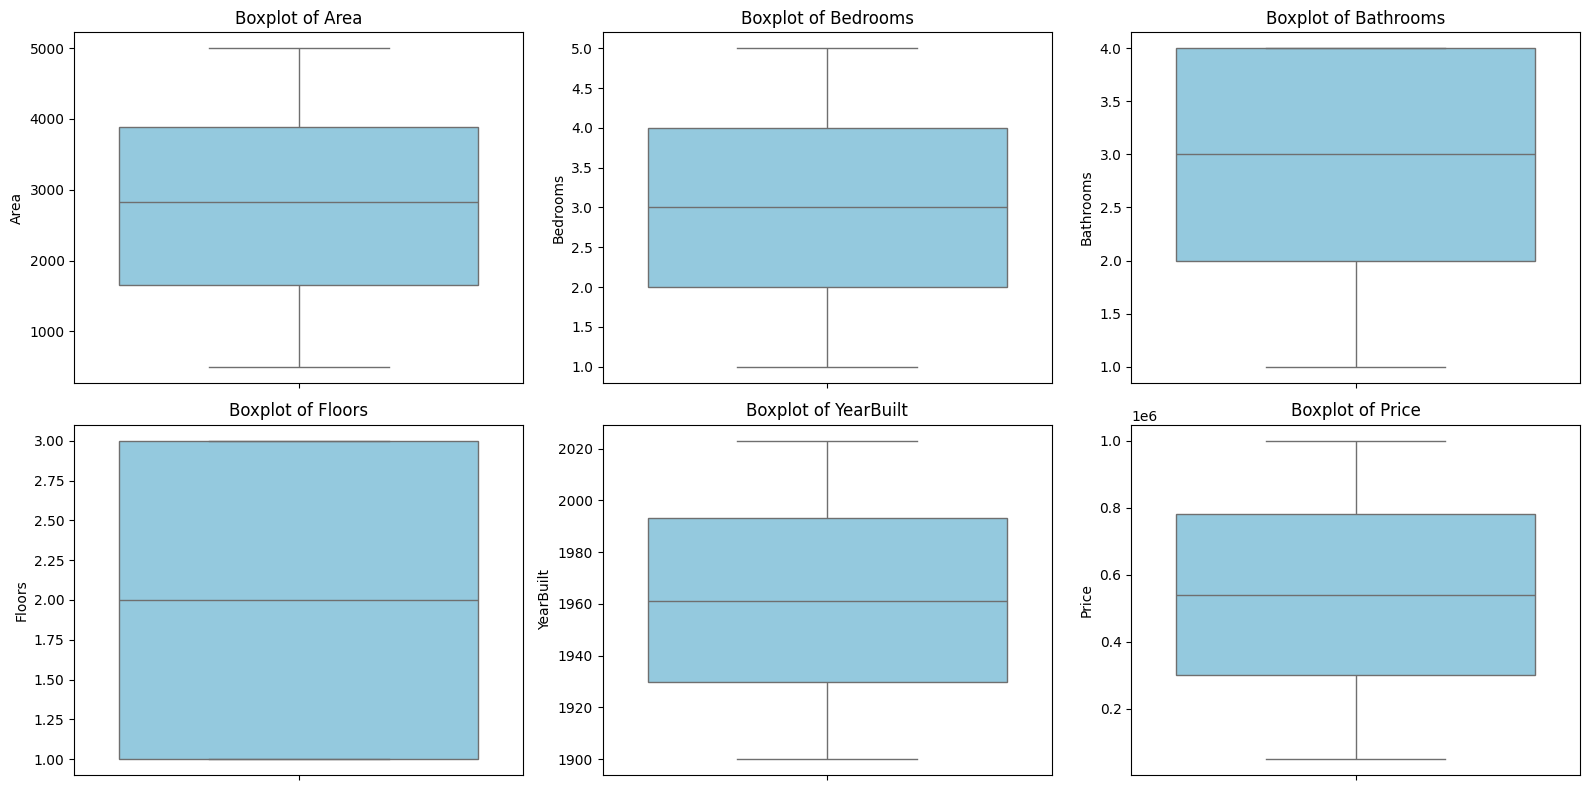

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

n = len(num_cols)
cols_per_row = 3
rows_needed = (n + cols_per_row - 1) // cols_per_row

fig, axes = plt.subplots(rows_needed, cols_per_row, figsize=(16, 4 * rows_needed))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(y=df_clean[col], ax=axes[i], color="skyblue")
    axes[i].set_title(f"Boxplot of {col}")

for j in range(n, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
cat_cols = df_clean.select_dtypes(include="object").columns.tolist()
print("Categorical columns:", cat_cols)

for col in cat_cols:
    print(f"\n{col}: {df_clean[col].nunique()} unique values")
    print(df_clean[col].value_counts())

Categorical columns: ['Location', 'Condition', 'Garage']

Location: 4 unique values
Location
Downtown    558
Urban       485
Suburban    483
Rural       474
Name: count, dtype: int64

Condition: 4 unique values
Condition
Fair         521
Excellent    511
Poor         507
Good         461
Name: count, dtype: int64

Garage: 2 unique values
Garage
No     1038
Yes     962
Name: count, dtype: int64


In [ ]:
df_encoded = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True, dtype=int)

print("Shape before:", df_clean.shape)
print("Shape after:", df_encoded.shape)
df_encoded.head()

Shape before: (2000, 10)
Shape after: (2000, 14)


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price,Location_Rural,Location_Suburban,Location_Urban,Condition_Fair,Condition_Good,Condition_Poor,Garage_Yes
0,1,1360,5,4,3,1970,149919,0,0,0,0,0,0,0
1,2,4272,5,4,3,1958,424998,0,0,0,0,0,0,0
2,3,3592,2,2,3,1938,266746,0,0,0,0,1,0,0
3,4,966,4,2,2,1902,244020,0,1,0,1,0,0,1
4,5,4926,1,4,2,1975,636056,0,0,0,1,0,0,1


In [ ]:
print(df_encoded.dtypes)
print("Any text columns left:", (df_encoded.dtypes == "object").sum())

Id                   int64
Area                 int64
Bedrooms             int64
Bathrooms            int64
Floors               int64
YearBuilt            int64
Price                int64
Location_Rural       int64
Location_Suburban    int64
Location_Urban       int64
Condition_Fair       int64
Condition_Good       int64
Condition_Poor       int64
Garage_Yes           int64
dtype: object
Any text columns left: 0


In [ ]:
from sklearn.model_selection import train_test_split

# Drop Id if it's still there
df_model = df_encoded.drop(columns=["Id"], errors="ignore")

X = df_model.drop(columns=["Price"])
y = df_model["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (1600, 12) Test: (400, 12)


In [ ]:
from sklearn.preprocessing import StandardScaler

# Original numeric features (only those that exist in X)
scale_cols = [c for c in ["Area", "Bedrooms", "Bathrooms", "Floors", "YearBuilt"] if c in X.columns]
print("Scaling:", scale_cols)

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit on TRAIN only, then apply to both
X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

X_train_scaled.head()

Scaling: ['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt']


,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location_Rural,Location_Suburban,Location_Urban,Condition_Fair,Condition_Good,Condition_Poor,Garage_Yes
968,1.314081,0.685758,1.316088,1.242260,-0.808673,0,0,1,0,0,0,0
240,-1.315960,-0.014889,0.414272,-1.236064,0.221883,0,0,0,0,1,0,0
819,-1.039194,-0.014889,1.316088,-1.236064,0.862499,0,0,1,0,1,0,1
692,-0.088966,-0.715536,0.414272,-1.236064,0.277589,1,0,0,0,0,1,1
420,0.393836,-0.715536,1.316088,-1.236064,0.528264,1,0,0,0,0,0,1


In [ ]:
print(X_train_scaled[scale_cols].describe().loc[["mean", "std"]].round(2))

      Area  Bedrooms  Bathrooms  Floors  YearBuilt
mean  -0.0      -0.0        0.0    -0.0       -0.0
std    1.0       1.0        1.0     1.0        1.0


In [ ]:
import joblib, os
os.makedirs("models", exist_ok=True)
joblib.dump(scaler, "models/scaler.pkl")

['models/scaler.pkl']

In [ ]:
df_fe = df_clean.copy()
REFERENCE_YEAR = 2026

# 1. Age of the house
df_fe["HouseAge"] = REFERENCE_YEAR - df_fe["YearBuilt"]

# 2. Total rooms (bedrooms + bathrooms)
df_fe["TotalRooms"] = df_fe["Bedrooms"] + df_fe["Bathrooms"]

# 3. Area per bedroom (+1 avoids division by zero)
df_fe["AreaPerBedroom"] = df_fe["Area"] / (df_fe["Bedrooms"] + 1)

# 4. Bathroom-to-bedroom ratio
df_fe["BathBedRatio"] = df_fe["Bathrooms"] / (df_fe["Bedrooms"] + 1)

# 5. Area per floor
df_fe["AreaPerFloor"] = df_fe["Area"] / df_fe["Floors"].replace(0, 1)

# 6. Is the house new? (built within the last 10 years)
df_fe["IsNew"] = (df_fe["HouseAge"] <= 10).astype(int)

# 7. Age group (categorical)
df_fe["AgeGroup"] = pd.cut(
    df_fe["HouseAge"],
    bins=[-1, 10, 30, 60, 200],
    labels=["New", "Modern", "Old", "Very Old"]
).astype(str)

df_fe.head()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price,HouseAge,TotalRooms,AreaPerBedroom,BathBedRatio,AreaPerFloor,IsNew,AgeGroup
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919,56,9,226.666667,0.666667,453.333333,0,Old
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998,68,9,712.000000,0.666667,1424.000000,0,Very Old
2,3,3592,2,2,3,1938,Downtown,Good,No,266746,88,4,1197.333333,0.666667,1197.333333,0,Very Old
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020,124,6,193.200000,0.400000,483.000000,0,Very Old
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056,51,5,2463.000000,2.000000,2463.000000,0,Old


In [ ]:
new_feats = ["HouseAge", "TotalRooms", "AreaPerBedroom", "BathBedRatio", "AreaPerFloor", "IsNew"]
print(df_fe[new_feats + ["Price"]].corr()["Price"].sort_values(ascending=False).round(3))

Price             1.000
IsNew             0.013
BathBedRatio     -0.004
HouseAge         -0.005
TotalRooms       -0.012
AreaPerBedroom   -0.015
AreaPerFloor     -0.046
Name: Price, dtype: float64


In [ ]:
df_fe = df_fe.drop(columns=["YearBuilt"], errors="ignore")
print(df_fe.columns.tolist())

['Id', 'Area', 'Bedrooms', 'Bathrooms', 'Floors', 'Location', 'Condition', 'Garage', 'Price', 'HouseAge', 'TotalRooms', 'AreaPerBedroom', 'BathBedRatio', 'AreaPerFloor', 'IsNew', 'AgeGroup']


In [ ]:
df_fe = df_clean.copy()
REFERENCE_YEAR = 2026

df_fe["HouseAge"] = REFERENCE_YEAR - df_fe["YearBuilt"]
df_fe["TotalRooms"] = df_fe["Bedrooms"] + df_fe["Bathrooms"]
df_fe["AreaPerBedroom"] = df_fe["Area"] / (df_fe["Bedrooms"] + 1)
df_fe["BathBedRatio"] = df_fe["Bathrooms"] / (df_fe["Bedrooms"] + 1)
df_fe["AreaPerFloor"] = df_fe["Area"] / df_fe["Floors"].replace(0, 1)
df_fe["IsNew"] = (df_fe["HouseAge"] <= 10).astype(int)
df_fe["AgeGroup"] = pd.cut(
    df_fe["HouseAge"],
    bins=[-1, 10, 30, 60, 200],
    labels=["New", "Modern", "Old", "Very Old"]
).astype(str)

df_fe = df_fe.drop(columns=["YearBuilt"], errors="ignore")

print(df_fe.columns.tolist())
df_fe.head()

['Id', 'Area', 'Bedrooms', 'Bathrooms', 'Floors', 'Location', 'Condition', 'Garage', 'Price', 'HouseAge', 'TotalRooms', 'AreaPerBedroom', 'BathBedRatio', 'AreaPerFloor', 'IsNew', 'AgeGroup']


,Id,Area,Bedrooms,Bathrooms,Floors,Location,Condition,Garage,Price,HouseAge,TotalRooms,AreaPerBedroom,BathBedRatio,AreaPerFloor,IsNew,AgeGroup
0,1,1360,5,4,3,Downtown,Excellent,No,149919,56,9,226.666667,0.666667,453.333333,0,Old
1,2,4272,5,4,3,Downtown,Excellent,No,424998,68,9,712.000000,0.666667,1424.000000,0,Very Old
2,3,3592,2,2,3,Downtown,Good,No,266746,88,4,1197.333333,0.666667,1197.333333,0,Very Old
3,4,966,4,2,2,Suburban,Fair,Yes,244020,124,6,193.200000,0.400000,483.000000,0,Very Old
4,5,4926,1,4,2,Downtown,Fair,Yes,636056,51,5,2463.000000,2.000000,2463.000000,0,Old


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

results = []
trained = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    trained[name] = model

    mse = mean_squared_error(y_test, pred)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test, pred),
    })

results_df = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
results_df.round(4)

,Model,MAE,MSE,RMSE,R2
0,Ridge Regression,243244.0943,7.832132e+10,279859.4654,-0.0067
1,Linear Regression,243241.9776,7.832147e+10,279859.7258,-0.0067
2,Gradient Boosting,245284.3575,8.055998e+10,283830.9083,-0.0355
3,Random Forest,251003.0876,8.490261e+10,291380.5184,-0.0913
4,Decision Tree,329752.9375,1.618576e+11,402315.2437,-1.0805


In [ ]:
from sklearn.model_selection import cross_val_score

cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring="r2")
    train_r2 = r2_score(y_train, trained[name].predict(X_train_scaled))
    cv_rows.append({
        "Model": name,
        "Train R2": train_r2,
        "CV R2 (mean)": scores.mean(),
        "CV R2 (std)": scores.std(),
    })

pd.DataFrame(cv_rows).round(4)

,Model,Train R2,CV R2 (mean),CV R2 (std)
0,Linear Regression,0.0099,-0.0093,0.0071
1,Ridge Regression,0.0099,-0.0092,0.0070
2,Decision Tree,1.0000,-1.0006,0.0567
3,Random Forest,0.8528,-0.0618,0.0155
4,Gradient Boosting,0.1998,-0.0541,0.0184


/tmp/ipykernel_1976/2842657982.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="R2", y="Model", ax=axes[0], palette="viridis")
/tmp/ipykernel_1976/2842657982.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="RMSE", y="Model", ax=axes[1], palette="magma")


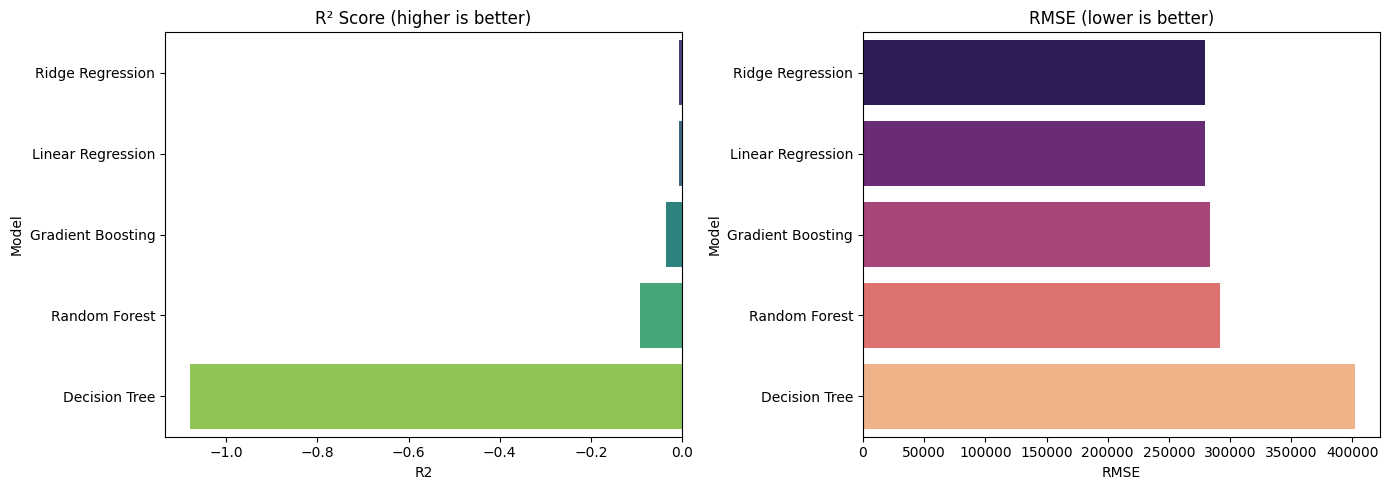

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=results_df, x="R2", y="Model", ax=axes[0], palette="viridis")
axes[0].set_title("R² Score (higher is better)")

sns.barplot(data=results_df, x="RMSE", y="Model", ax=axes[1], palette="magma")
axes[1].set_title("RMSE (lower is better)")

plt.tight_layout()
plt.show()

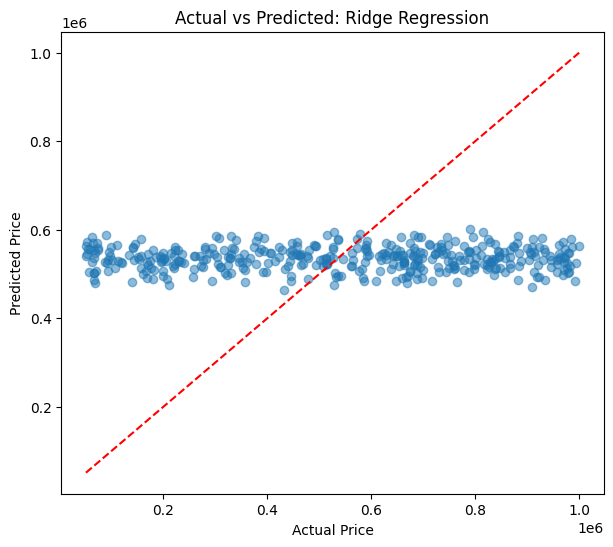

Best model: Ridge Regression


In [ ]:
best_name = results_df.loc[0, "Model"]
best_model = trained[best_name]
best_pred = best_model.predict(X_test_scaled)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title(f"Actual vs Predicted: {best_name}")
plt.show()

print("Best model:", best_name)

In [ ]:
import joblib, os
os.makedirs("models", exist_ok=True)

joblib.dump(best_model, "models/best_model.pkl")
joblib.dump(X_train_scaled.columns.tolist(), "models/feature_columns.pkl")
joblib.dump(scaler, "models/scaler.pkl")
print("Saved: best_model.pkl, feature_columns.pkl, scaler.pkl")

Saved: best_model.pkl, feature_columns.pkl, scaler.pkl


In [ ]:
import shutil
from google.colab import files

# Make sure the models exist
import os
print(os.listdir("models"))

# Zip the models folder and download it
shutil.make_archive("models", "zip", "models")
files.download("models.zip")

['feature_columns.pkl', 'best_model.pkl', 'scaler.pkl']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

def get_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2 Score": r2_score(y_true, y_pred),
    }

# All models on the test set
rows = []
for name, model in trained.items():
    m = get_metrics(y_test, model.predict(X_test_scaled))
    rows.append({"Model": name, **m})

final_table = pd.DataFrame(rows).sort_values("R2 Score", ascending=False).reset_index(drop=True)
final_table.index += 1
display(final_table.style.format({
    "MAE": "{:,.2f}", "MSE": "{:,.2f}", "RMSE": "{:,.2f}", "R2 Score": "{:.4f}"
}).background_gradient(subset=["R2 Score"], cmap="Greens"))

# Best model: train vs test
best_name = final_table.loc[1, "Model"]
best_model = trained[best_name]

compare = pd.DataFrame({
    "Train": get_metrics(y_train, best_model.predict(X_train_scaled)),
    "Test": get_metrics(y_test, best_model.predict(X_test_scaled)),
}).round(4)

print(f"Best model: {best_name}")
display(compare)

# Save for your GitHub repo and report
final_table.to_csv("model_comparison.csv", index_label="Rank")

,Model,MAE,MSE,RMSE,R2 Score
1,Ridge Regression,"243,244.09","78,321,320,400.26","279,859.47",-0.0067
2,Linear Regression,"243,241.98","78,321,466,146.03","279,859.73",-0.0067
3,Gradient Boosting,"245,284.36","80,559,984,532.86","283,830.91",-0.0355
4,Random Forest,"251,003.09","84,902,606,512.83","291,380.52",-0.0913
5,Decision Tree,"329,752.94","161,857,555,335.17","402,315.24",-1.0805


Best model: Ridge Regression


,Train,Test
MAE,2.371220e+05,2.432441e+05
MSE,7.525838e+10,7.832132e+10
RMSE,2.743326e+05,2.798595e+05
R2 Score,9.900000e-03,-6.700000e-03


In [ ]:
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import time

rf_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", 1.0],
}

start = time.time()
rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42),
    param_distributions=rf_params,
    n_iter=20,
    cv=5,
    scoring="r2",
    random_state=42,
    n_jobs=-1,
    verbose=1,
)
rf_search.fit(X_train_scaled, y_train)

print("Time:", round(time.time() - start, 1), "sec")
print("Best RF params:", rf_search.best_params_)
print("Best RF CV R2:", round(rf_search.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Time: 77.0 sec
Best RF params: {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 10}
Best RF CV R2: -0.0126


In [ ]:
gb_params = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 4, 5],
    "subsample": [0.8, 1.0],
}

start = time.time()
gb_search = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_grid=gb_params,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1,
)
gb_search.fit(X_train_scaled, y_train)

print("Time:", round(time.time() - start, 1), "sec")
print("Best GB params:", gb_search.best_params_)
print("Best GB CV R2:", round(gb_search.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Time: 42.4 sec
Best GB params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Best GB CV R2: -0.0253


In [ ]:
gb_params = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 4, 5],
    "subsample": [0.8, 1.0],
}

start = time.time()
gb_search = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_grid=gb_params,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1,
)
gb_search.fit(X_train_scaled, y_train)

print("Time:", round(time.time() - start, 1), "sec")
print("Best GB params:", gb_search.best_params_)
print("Best GB CV R2:", round(gb_search.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Time: 45.0 sec
Best GB params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Best GB CV R2: -0.0253


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

def evaluate(model, name):
    pred = model.predict(X_test_scaled)
    mse = mean_squared_error(y_test, pred)
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2 Score": r2_score(y_test, pred),
    }

comparison = pd.DataFrame([
    evaluate(trained["Random Forest"], "Random Forest (Before)"),
    evaluate(rf_search.best_estimator_, "Random Forest (After)"),
    evaluate(trained["Gradient Boosting"], "Gradient Boosting (Before)"),
    evaluate(gb_search.best_estimator_, "Gradient Boosting (After)"),
])

display(comparison.round(4))
comparison.to_csv("tuning_comparison.csv", index=False)

,Model,MAE,MSE,RMSE,R2 Score
0,Random Forest (Before),251003.0876,8.490261e+10,291380.5184,-0.0913
1,Random Forest (After),246257.5016,8.045842e+10,283651.9274,-0.0342
2,Gradient Boosting (Before),245284.3575,8.055998e+10,283830.9083,-0.0355
3,Gradient Boosting (After),243389.1255,7.924954e+10,281512.9415,-0.0186


In [ ]:
def improvement(before, after):
    b = comparison.set_index("Model")
    return {
        "R2 change": round(b.loc[after, "R2 Score"] - b.loc[before, "R2 Score"], 4),
        "RMSE change": round(b.loc[after, "RMSE"] - b.loc[before, "RMSE"], 2),
    }

print("Random Forest:", improvement("Random Forest (Before)", "Random Forest (After)"))
print("Gradient Boosting:", improvement("Gradient Boosting (Before)", "Gradient Boosting (After)"))

Random Forest: {'R2 change': np.float64(0.0571), 'RMSE change': np.float64(-7728.59)}
Gradient Boosting: {'R2 change': np.float64(0.0168), 'RMSE change': np.float64(-2317.97)}


/tmp/ipykernel_1976/2376962026.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison, x="R2 Score", y="Model", ax=axes[0], palette="viridis")
/tmp/ipykernel_1976/2376962026.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison, x="RMSE", y="Model", ax=axes[1], palette="magma")


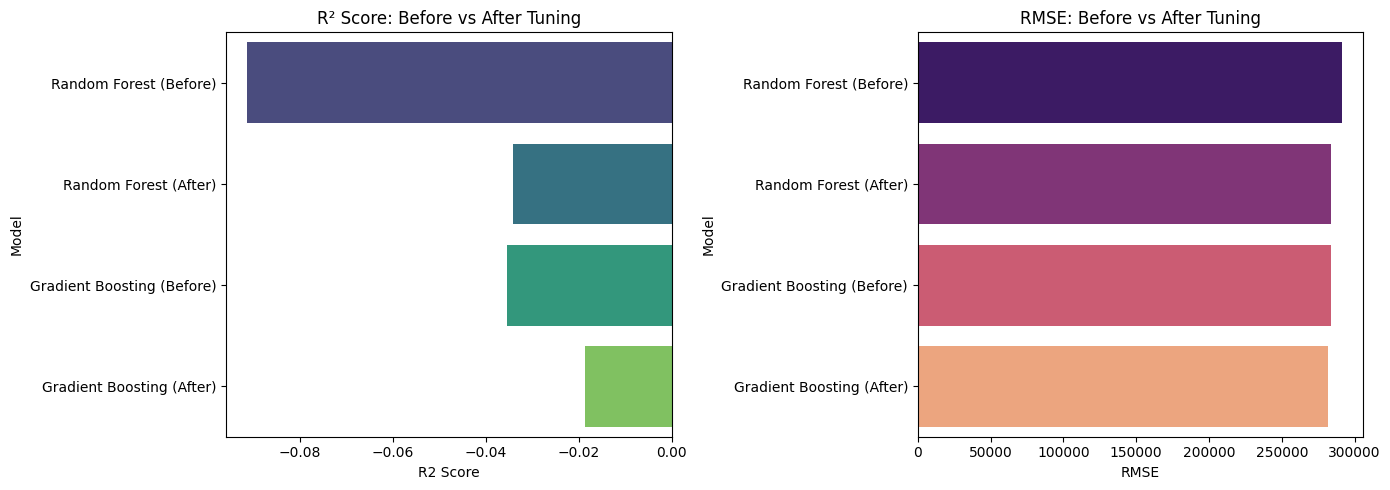

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=comparison, x="R2 Score", y="Model", ax=axes[0], palette="viridis")
axes[0].set_title("R² Score: Before vs After Tuning")

sns.barplot(data=comparison, x="RMSE", y="Model", ax=axes[1], palette="magma")
axes[1].set_title("RMSE: Before vs After Tuning")

plt.tight_layout()
plt.savefig("tuning_comparison.png", dpi=150)
plt.show()

In [ ]:
candidates = {
    "Random Forest (Tuned)": rf_search.best_estimator_,
    "Gradient Boosting (Tuned)": gb_search.best_estimator_,
    **{f"{k} (Default)": v for k, v in trained.items()},
}

scores = {name: r2_score(y_test, m.predict(X_test_scaled)) for name, m in candidates.items()}
final_name = max(scores, key=scores.get)
final_model = candidates[final_name]

print("Final model:", final_name)
print("Test R2:", round(scores[final_name], 4))

Final model: Ridge Regression (Default)
Test R2: -0.0067


In [ ]:
import joblib, os
os.makedirs("models", exist_ok=True)

joblib.dump(final_model, "models/best_model.pkl", compress=3)
joblib.dump(X_train_scaled.columns.tolist(), "models/feature_columns.pkl")
joblib.dump(scaler, "models/scaler.pkl")

print("Saved. Model size:", round(os.path.getsize("models/best_model.pkl") / 1e6, 2), "MB")

# Test that it loads and predicts
loaded = joblib.load("models/best_model.pkl")
print("Sample prediction:", loaded.predict(X_test_scaled.iloc[:3]))
print("Actual values:    ", y_test.iloc[:3].values)

Saved. Model size: 0.0 MB
Sample prediction: [521977.57396705 549094.7030053  487190.31046324]
Actual values:     [514764 694256  66375]


In [ ]:
import joblib, numpy as np, sklearn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pred = final_model.predict(X_test_scaled)
mse = mean_squared_error(y_test, pred)

meta = {
    "model_name": final_name,
    "reference_year": 2026,
    "categories": {c: sorted(df_fe[c].unique().tolist()) for c in ["Location", "Condition", "Garage"]},
    "ranges": {
        "Area": (float(df_fe["Area"].min()), float(df_fe["Area"].max()), float(df_fe["Area"].median())),
        "Bedrooms": (int(df_fe["Bedrooms"].min()), int(df_fe["Bedrooms"].max())),
        "Bathrooms": (int(df_fe["Bathrooms"].min()), int(df_fe["Bathrooms"].max())),
        "Floors": (int(df_fe["Floors"].min()), int(df_fe["Floors"].max())),
        "YearBuilt": (int(df_clean["YearBuilt"].min()), int(df_clean["YearBuilt"].max())),
    },
    "price_stats": {
        "mean": float(df_fe["Price"].mean()),
        "median": float(df_fe["Price"].median()),
        "min": float(df_fe["Price"].min()),
        "max": float(df_fe["Price"].max()),
    },
    "price_percentiles": np.percentile(df_fe["Price"], np.arange(0, 101)).tolist(),
    "test_metrics": {
        "MAE": float(mean_absolute_error(y_test, pred)),
        "RMSE": float(np.sqrt(mse)),
        "R2": float(r2_score(y_test, pred)),
    },
}

joblib.dump(meta, "models/metadata.pkl")
print("sklearn version:", sklearn.__version__)   # needed for requirements.txt
print(meta["categories"])

sklearn version: 1.6.1
{'Location': ['Downtown', 'Rural', 'Suburban', 'Urban'], 'Condition': ['Excellent', 'Fair', 'Good', 'Poor'], 'Garage': ['No', 'Yes']}


In [39]:
import shutil
from google.colab import files

shutil.make_archive("models", "zip", "models")
files.download("models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>